<a href="https://colab.research.google.com/github/shreeyeshapore/ML-Practicals/blob/main/Basic_Perceptron_MLP_Activation_Comparison_Shreeyesha.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Experiment: Perceptron and Multilayer Perceptron (MLP)



## Aim
1. Implement a single-layer perceptron from scratch.
2. Train a Multilayer Perceptron (MLP) using Scikit-learn.
3. Compare different activation functions.

**Libraries:** NumPy, Matplotlib and Scikit-learn

## Part A: Single-Layer Perceptron from Scratch

### 1. Import libraries and create simple data

In [ ]:
### 1. Import libraries and create simple data

import numpy as np
import matplotlib.pyplot as plt

# Simple linearly separable data (two input features)
X = np.array([
    [2, 2],
    [3, 2],
    [2, 3],
    [6, 6],
    [7, 6],
    [6, 7]
])

y = np.array([0, 0, 0, 1, 1, 1])

print("Input data:")
print(X)
print("Target values:", y)

Input data:
[[2 2]
 [3 2]
 [2 3]
 [6 6]
 [7 6]
 [6 7]]
Target values: [0 0 0 1 1 1]


### 2. Implement the Perceptron algorithm

In [ ]:
### 2. Implement the Perceptron algorithm

# Initialize weights and bias
weights = np.zeros(2)
bias = 0
learning_rate = 0.2
epochs = 15

# Train the perceptron
for epoch in range(epochs):
    for i in range(len(X)):
        # Calculate weighted sum
        total = np.dot(X[i], weights) + bias

        # Step activation function
        prediction = 1 if total >= 0 else 0

        # Calculate error and update weights
        error = y[i] - prediction
        weights = weights + learning_rate * error * X[i]
        bias = bias + learning_rate * error

print("Final weights:", weights)
print("Final bias:", bias)

Final weights: [-0.2  0.6]
Final bias: -2.1999999999999997


### 3. Test the Perceptron

In [ ]:
### 3. Test the Perceptron

# Predict output for all input samples
predictions = []

for sample in X:
    total = np.dot(sample, weights) + bias
    prediction = 1 if total >= 0 else 0
    predictions.append(prediction)

print("Actual Output:    ", y)
print("Predicted Output: ", predictions)


Actual Output:     [0 0 0 1 1 1]
Predicted Output:  [0, 0, 0, 1, 1, 1]


## Part B: Multilayer Perceptron using Scikit-learn

### 4. Load a sample dataset

In [ ]:
## Part B: Multilayer Perceptron using Scikit-learn

### 4. Load a sample dataset

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score

# Use two Iris classes for a simple binary classification problem
iris = load_iris()
X = iris.data[:100, 1:3]
y = iris.target[:100]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=10
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 75
Testing samples: 25


### 5. Train an MLP model

In [ ]:
### 5. Train an MLP model

# Train MLP with Tanh activation
mlp = MLPClassifier(
    hidden_layer_sizes=(8,),
    activation="tanh",
    max_iter=1200,
    random_state=10
)

mlp.fit(X_train, y_train)

y_pred = mlp.predict(X_test)

print("Actual values:   ", y_test)
print("Predicted values:", y_pred)
print("Accuracy:", round(accuracy_score(y_test, y_pred) * 100, 2), "%")

Actual values:    [0 0 0 0 1 0 1 0 0 1 0 0 1 1 1 1 1 0 1 0 1 1 1 0 1]
Predicted values: [0 0 0 0 1 0 1 0 0 1 0 0 1 1 1 1 1 0 1 0 1 1 1 0 1]
Accuracy: 100.0 %


### 6. Compare different activation functions

We train the same MLP using ReLU, tanh and logistic (sigmoid) activation functions and compare their test accuracy.

In [ ]:
### 6. Compare different activation functions

# Compare Tanh, ReLU and Logistic activation functions
activation_functions = ["tanh", "relu", "logistic"]
results = []

for activation in activation_functions:
    model = MLPClassifier(
        hidden_layer_sizes=(8,),
        activation=activation,
        max_iter=1200,
        random_state=10
    )

    model.fit(X_train, y_train)
    prediction = model.predict(X_test)
    accuracy = accuracy_score(y_test, prediction)

    results.append(accuracy)
    print(activation, "Accuracy:", round(accuracy * 100, 2), "%")

tanh Accuracy: 100.0 %
relu Accuracy: 100.0 %
logistic Accuracy: 100.0 %


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1200) reached and the optimization hasn't converged yet.
  warnings.warn(


### 7. Plot activation function comparison

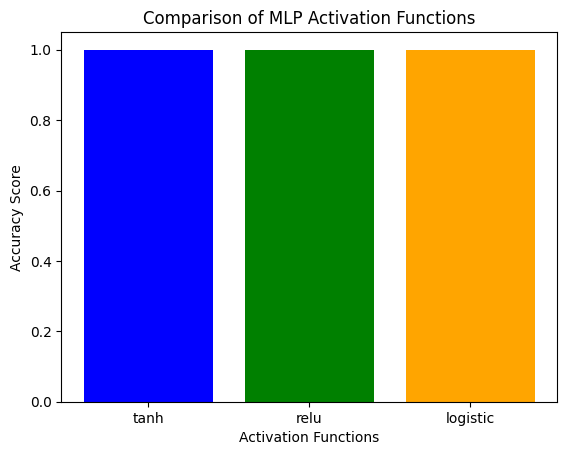

In [ ]:
### 7. Plot activation function comparison

plt.bar(activation_functions, results, color=["blue", "green", "orange"])
plt.xlabel("Activation Functions")
plt.ylabel("Accuracy Score")
plt.title("Comparison of MLP Activation Functions")
plt.ylim(0, 1.05)
plt.show()

## Observations
1.A single-layer perceptron classifies data using weights, bias and a step activation function.

2.During training, the weights and bias are adjusted based on prediction errors.

3.An MLP consists of an input layer, hidden layer(s) and an output layer.

4.Different activation functions such as ReLU, tanh and logistic influence model performance.

5.The classification accuracy varies depending on the activation function and network parameters.

## Result
A single-layer perceptron was successfully implemented and trained from scratch. An MLP classifier was trained using Scikit-learn, and the performance of different activation functions, namely ReLU, tanh and logistic, was compared using test accuracy.